# Experimental: cross-section in height from pressure-level data, without vertical interpolation

**This is an experimental example.** It is a variant of [cross_section_height_pl_orog.ipynb](cross_section_height_pl_orog.ipynb), which reproduces the Metview gallery example [Cross Section in Height for Pressure Level Data with Orography](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_height_pl_orog.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. That notebook interpolates the temperature from the pressure levels to regular height levels (0 to 3000 m every 20 m) with the `pressure_to_height()` helper. **This variant does not use vertical interpolation.** The temperature is contoured directly on the heights of the pressure levels, which form an uneven, curvilinear grid: each level has a different height at each point of the line. The horizontal part (the line and the regridding onto it) uses the new `earthkit.geo.polyline` module, whose interface may still change. The heights of the levels are computed with `earthkit.meteo.vertical.geometric_height_from_geopotential`, through the `geometric_height()` helper.

This is the simplified version of the [raw notebook](../raw/cross_section_height_pl_orog_direct.ipynb). It uses the `cross_section()`, `geometric_height()` and `orography()` helpers from [../xsection.py](../xsection.py) instead of the hand-written regridding, level sorting, height conversion and Xarray steps.

The notebook reads a GRIB file. It contains forecast data of 2020-08-22 00 UTC.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import sys

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import cross_section, geometric_height, orography

## Load the data

The file contains the temperature `t` and the geopotential `z` on the pressure levels 1000, 925, 850, 700, 400, 500 and 300 hPa (the order of the levels in the file is not monotonic: 400 comes before 500, the `cross_section()` helper sorts the levels), for the forecast step of 12 h, and the surface geopotential `z` from the analysis (step 0). It is a GRIB1 file on a regular 0.5° latitude-longitude grid over the area 40–51°N, 93–84°W. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_orog.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_orog.grib:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

15 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
1,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
2,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
3,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
4,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll
5,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature, the geopotential and the surface geopotential

We select `t` and `z` on the pressure levels, which gives 7 fields each, in one fieldlist, and `z` at the surface, which gives a single field, in another one. The geopotential is in m²/s². The surface geopotential is kept apart because it has a different forecast step than the other fields. The cell prints the pressure levels of the fields in the order they have in the file.

In [3]:
tz = ds.sel({"parameter.variable": ["t", "z"], "vertical.level_type": "pressure"})
zs = ds.sel({"parameter.variable": "z", "vertical.level_type": "surface"})

t_levels = [f.get("vertical.level") for f in tz.sel({"parameter.variable": "t"})]
print(len(tz), "fields in total on the pressure levels")
print(len(t_levels), "t fields, levels (hPa):", t_levels)
print(len(zs), "surface z field")

14 fields in total on the pressure levels
7 t fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
1 surface z field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (50.21°N, 91.82°W) to (40.82°N, 84.71°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [4]:
lats, lons = sample_polyline([50.21, 40.82], [-91.82, -84.71], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(50.21), np.float64(-91.82)) (np.float64(40.82), np.float64(-84.71))


## Compute the cross-section on the line

The `cross_section()` helper from `../xsection.py` does the regridding and builds the Xarray Dataset in one call. The helper uses nearest-neighbour interpolation by default, so each point of the line gets the value of the nearest grid point. The levels are returned sorted by increasing pressure, from 300 to 1000 hPa. Here the levels must be sorted: we contour the temperature directly on the heights of the levels, and unsorted levels would make neighbouring cells of the grid overlap. We call the helper twice: for the temperature and the geopotential on the pressure levels, which gives variables `t` and `z` on `level` (hPa) and `distance` (km, cumulative along the line), and for the surface geopotential, which has a different forecast step and cannot be converted together with the other fields. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

During the regridding earthkit may log an `Error setting gridSpec` message with a traceback (a `GeocalculusError`), and MIR may print some `ECCODES` lines about the grid. Both are harmless: the regridding is not affected and the result is correct.

In [5]:
xs = cross_section(tz, lats, lons)  # t and z on the pressure levels
xs_zs = cross_section(zs, lats, lons)  # surface z, in a separate call
xs

Error setting gridSpec={"type": "unstructured_ll", "uid": "6d76a7b0bf55a727a549421e77eda507"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

Error setting gridSpec={"type": "unstructured_ll", "uid": "6d76a7b0bf55a727a549421e77eda507"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

<xarray.Dataset> Size: 27kB
Dimensions:                  (level: 7, distance: 200)
Coordinates:
  * level                    (level) int64 56B 300 400 500 700 850 925 1000
  * distance                 (distance) float64 2kB 0.0 5.831 ... 1.182e+03
    latitude                 (distance) float64 2kB 50.21 50.16 ... 40.87 40.82
    longitude                (distance) float64 2kB -91.82 -91.78 ... -84.71
    forecast_reference_time  datetime64[ns] 8B 2020-08-22
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    t                        (level, distance) float64 11kB 236.3 ... 297.4
    z                        (level, distance) float64 11kB 9.306e+04 ... 1.2...
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Compute the heights

The `geometric_height()` helper converts the geopotential to geometric height in m. It gives the height `H` of each pressure level at each point of the line. The `orography()` helper does the same for the surface geopotential and gives the height of the surface, which is the orography. The cell prints the range of the height of the 1000 hPa level and of the orography. The 1000 hPa level is below the ground everywhere on this line, because the orography is higher than the height of this level.

In [6]:
H = geometric_height(xs["z"])  # m, (level, distance)
orog = orography(xs_zs["z"])  # m, (distance)

print(f"height of the 1000 hPa level: {float(H.sel(level=1000).min()):.0f} to {float(H.sel(level=1000).max()):.0f} m")
print(f"orography: {float(orog.min()):.0f} to {float(orog.max()):.0f} m")

height of the 1000 hPa level: 82 to 125 m
orography: 172 to 582 m


## Check that the lowest level is below the ground

Without vertical interpolation there is no need for target heights, and the temperature stays on the pressure levels, converted from K to °C by subtracting 273.15 (Metview uses 273.16, the difference of 0.01 °C is not visible). This works here for two reasons. First, the lowest level, 1000 hPa, is below the ground everywhere on the line, so the ground, which is drawn on top, covers the part of the plot where there are no data below the lowest level. Second, the levels above the plotted range, up to the 300 hPa level, are outside the view, which stops at 3000 m. Together this means that no extrapolation is needed in the visible area. The cell prints the range of the height of each level along the line, and asserts that the lowest level is below the ground at every point and that the levels do not cross.

In [7]:
for p in H["level"].values[::-1]:
    h = H.sel(level=p)
    print(f"{p:5d} hPa: height from {float(h.min()):6.0f} to {float(h.max()):6.0f} m")
print(f"orography: {float(orog.min()):.0f} to {float(orog.max()):.0f} m")
assert (H.sel(level=1000) < orog).all(), "the lowest level must be below the ground at every point"
assert (H.diff("level") < 0).all(), "the levels must not cross: the height must decrease as the pressure increases"
print("the lowest level is below the ground everywhere, and the height decreases as pressure increases at every point")

 1000 hPa: height from     82 to    125 m
  925 hPa: height from    753 to    801 m
  850 hPa: height from   1476 to   1525 m
  700 hPa: height from   3097 to   3147 m
  500 hPa: height from   5762 to   5819 m
  400 hPa: height from   7442 to   7509 m
  300 hPa: height from   9502 to   9575 m
orography: 172 to 582 m
the lowest level is below the ground everywhere, and the height decreases as pressure increases at every point


## Convert the temperature to °C and build the Dataset

The temperature is converted from K to °C, and its `units` attribute is updated. We keep only the temperature `t` on the dimensions `level` (hPa) and `distance` (km), add the height of each level as a two-dimensional coordinate `height` (m) on (`level`, `distance`), which is the curvilinear vertical coordinate, and add the orography on `distance` only.

In [8]:
# temperature: K -> degC
xs["t"] = xs["t"] - 273.15
xs["t"].attrs["units"] = "degC"

# keep only the temperature, add the height of the levels as a 2-D coordinate and the orography
xs = xs[["t"]].assign_coords(height=H)
xs["orography"] = orog
xs

<xarray.Dataset> Size: 29kB
Dimensions:                  (level: 7, distance: 200)
Coordinates:
  * level                    (level) int64 56B 300 400 500 700 850 925 1000
  * distance                 (distance) float64 2kB 0.0 5.831 ... 1.182e+03
    latitude                 (distance) float64 2kB 50.21 50.16 ... 40.87 40.82
    longitude                (distance) float64 2kB -91.82 -91.78 ... -84.71
    height                   (level, distance) float64 11kB 9.503e+03 ... 124.7
    forecast_reference_time  datetime64[ns] 8B 2020-08-22
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    t                        (level, distance) float64 11kB -36.88 ... 24.22
    orography                (distance) float64 2kB 372.8 372.8 ... 222.5 222.5
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Plot the cross-section on the heights of the levels

We plot the filled contours of temperature on the curvilinear grid (distance, height of the level), with a non-map earthkit-plots `Subplot`. The style is the same as in the interpolated notebook, so the two plots can be compared directly. The levels go from 4 to 25 °C every 1 °C. The colour map is the matplotlib `RdYlBu_r`, from blue through pale yellow to red. This is an approximate alternative to the Metview palette (pale blue, olive, yellow, orange and red), whose hues are noticeably different. Contour lines every 1 °C are drawn in charcoal, with a label every 2 °C. The colour bar is added with the `legend()` method of the figure. The orography is added with `fill_between()` and drawn in charcoal from the surface height down to 0 m, on top of the temperature. The vertical axis goes from 0 to 3000 m.

**How the contouring works.** Matplotlib's `contour`/`contourf` work on the quadrilateral cells of the grid. Here a cell is bounded by two neighbouring levels and two neighbouring points of the line. Isotherms cross the edges of the cells where the temperature, interpolated linearly along the edge, equals the contour value, and these crossings are joined inside each cell. Along a column, i.e. at a point of the line, the edge interpolation is linear in height between the levels, the same as in the vertical interpolation of the other notebook. The two plots can still differ for two reasons:

- **Resampling onto regular heights.** The other notebook samples the profile every 20 m. The profile is piecewise linear with a bend at each level height, and a 20 m step does not, in general, hit the bend exactly. So near the level heights (e.g. 925 hPa at about 750–800 m and 850 hPa at about 1480–1530 m) the isotherms of the interpolated plot can be shifted slightly, even at the points of the line.
- **Joining neighbouring columns.** Between the points of the line, the isotherms are drawn inside the cells of a different grid: the curvilinear (distance, level height) grid here, and the regular (distance, height) grid in the other notebook. So the lines between the points can be joined slightly differently.

Between the 1000 and 925 hPa levels (about 100 and 750 m) the cells are thick, and the ground covers the part below the lowest level. The temperature above the 300 hPa level is not needed, as the axis stops at 3000 m.

**Earthkit-plots was used for the plot.** `contourf()` and `contour()` of earthkit-plots cannot take a two-dimensional `height` coordinate by name (`x="distance", y="height"` gives an error, because the dimensions of x and y do not match), but they accept the two-dimensional coordinate arrays `x` and `y` of the grid with the same shape as the data, here the distance, repeated for each level, and the height of the levels. So no matplotlib call is needed for the contouring.

The 7 ticks of the horizontal axis are where the line crosses the whole longitudes 91°W, 90°W, …, 85°W, as in Metview. Their distance and latitude are found by linear interpolation along the sampled points, because they are not at sampled points. The labels have the latitude with up to 2 decimals (a trailing zero is dropped, as in Metview: "41.2°N/85°W") and the longitude in whole degrees.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()`. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-height section.
- The axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

['49.13°N/91°W', '47.81°N/90°W', '46.49°N/89°W', '45.17°N/88°W', '43.84°N/87°W', '42.52°N/86°W', '41.2°N/85°W']


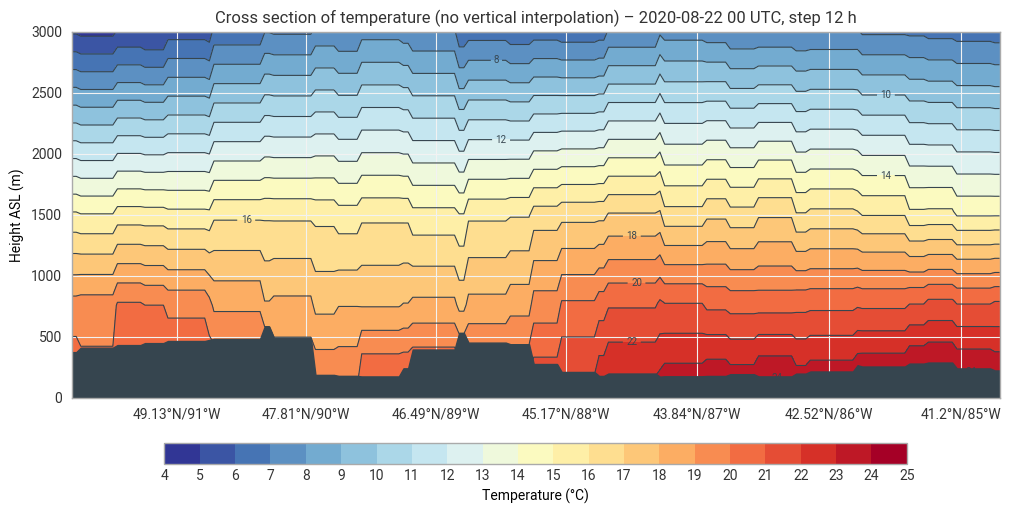

In [9]:
levels_t = list(range(4, 26))

# 7 ticks where the line crosses the longitudes 91W ... 85W (lons increase along the line)
distance = xs["distance"].values
tick_lons = np.arange(-91, -84)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

chart = ekp.Subplot(figsize=(10, 5))
# coordinates of the curvilinear grid, with the same shape as the data: (level, point)
x_grid = xs["distance"].broadcast_like(xs["t"]).values
y_grid = xs["height"].values

chart.contourf(
    xs["t"].values,
    x=x_grid,
    y=y_grid,
    style=ekp.styles.Style(levels=levels_t, colors="RdYlBu_r", ticks=levels_t),
    resample=False,
)
chart.contour(
    xs["t"].values,
    x=x_grid,
    y=y_grid,
    style=ekp.styles.Contour(
        levels=levels_t,
        colors="#36454f",
        linewidths=0.8,
        labels=True,
        label_kwargs={"label_frequency": 2, "label_fmt": "%g"},
        legend_style=None,  # no second colour bar for the lines
    ),
    resample=False,
)
chart.figure.legend(label="Temperature (°C)")
# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs["orography"], 0, x=xs["distance"], color="#36454f", alpha=1)

ax = chart.ax
ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 3000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Height ASL (m)")
ax.set_title("Cross section of temperature (no vertical interpolation) – 2020-08-22 00 UTC, step 12 h")

chart.show()